In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split,GridSearchCV,StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.calibration import CalibratedClassifierCV,CalibrationDisplay
from sklearn.metrics import precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report,brier_score_loss
print("libraries imported successfully")

libraries imported successfully


In [3]:
file=r"C:\Users\RSC\Desktop\data sheets\project\data science project\customer_level_features.csv"
df = pd.read_csv(file)
df.head(5)

,CustomerID,Recency,Frequency,Monetary,AverageOrderValue,PurchaseTrend,CustomerTenure,Churn
0,C00001,33,2,708.23,354.115,0.0,98,0
1,C00002,41,3,1705.44,568.480,1.0,130,0
2,C00004,96,1,199.66,199.660,-1.0,96,0
3,C00006,74,2,1152.75,576.375,0.0,221,0
4,C00009,42,1,54.88,54.880,NaN,42,1


In [4]:
df['PurchaseTrend'] = df['PurchaseTrend'].fillna(0)

In [5]:
df['AverageOrderValue'] = df['AverageOrderValue'].astype(int)
df['Monetary'] = df['Monetary'].astype(int)
df['PurchaseTrend'] = df['PurchaseTrend'].astype(int)

In [6]:
print(df.dtypes)
print(df.shape)

CustomerID             str
Recency              int64
Frequency            int64
Monetary             int64
AverageOrderValue    int64
PurchaseTrend        int64
CustomerTenure       int64
Churn                int64
dtype: object
(55, 8)


In [7]:
#target and features
TARGET = "Churn"

feature_columns = [
    "AverageOrderValue",
    "Monetary",
    "PurchaseTrend"
]

x = df[feature_columns].copy()
y = df[TARGET].astype(int)

print(x.shape)
print(y.shape)

(55, 3)
(55,)


In [10]:
#train_test_split
x_development, x_test, y_development, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
x_train, x_validation, y_train, y_validation = train_test_split(
    x_development,
    y_development,
    test_size=0.25,
    random_state=42,
    stratify=y_development
)

print("Training:", x_train.shape)
print("Validation:", x_validation.shape)
print("Testing:", x_test.shape)


Training: (33, 3)
Validation: (11, 3)
Testing: (11, 3)


In [11]:
# PREPROCESSING PIPELINE

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, feature_columns)
    ]
)
preprocessor.fit(x_train,y_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``"

In [12]:
# RANDOM FOREST PIPELINE

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)
rf_pipeline.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['AverageOrderValue','Monetary','PurchaseTrend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not

In [13]:
parameter_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 8, None],
    "classifier__min_samples_leaf": [5, 10]
}

cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=cross_validation,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

best_model = grid_search.best_estimator_

print("\nBEST PARAMETERS:")
print(grid_search.best_params_)

print("\nBEST CROSS-VALIDATION ROC-AUC:")
print(grid_search.best_score_)


Fitting 5 folds for each of 12 candidates, totalling 60 fits

BEST PARAMETERS:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}

BEST CROSS-VALIDATION ROC-AUC:
0.6222222222222223


In [16]:
#  probablities and costs

validation_probabilities = best_model.predict_proba(
    x_validation
)[:, 1]
FN_COST = 100
FP_COST = 20

threshold_results = []

thresholds = np.arange(0.05, 0.96, 0.01)

for threshold in thresholds:

    validation_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        validation_predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        FN_COST * fn +
        FP_COST * fp
    )
threshold_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_validation,
            validation_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation,
            validation_predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_validation,
            validation_predictions,
            zero_division=0
        ),
        "Business_Cost": total_cost
    })
threshold_df = pd.DataFrame(threshold_results)

best_threshold_row = threshold_df.loc[
    threshold_df["Business_Cost"].idxmin()
]

best_threshold = best_threshold_row["Threshold"]

print("\nBEST THRESHOLD:")
print(best_threshold)

print("\nTHRESHOLD PERFORMANCE:")
print(best_threshold_row)


BEST THRESHOLD:
0.9500000000000002

THRESHOLD PERFORMANCE:
Threshold          0.95
TN                 6.00
FP                 0.00
FN                 5.00
TP                 0.00
Precision          0.00
Recall             0.00
F1                 0.00
Business_Cost    500.00
Name: 0, dtype: float64


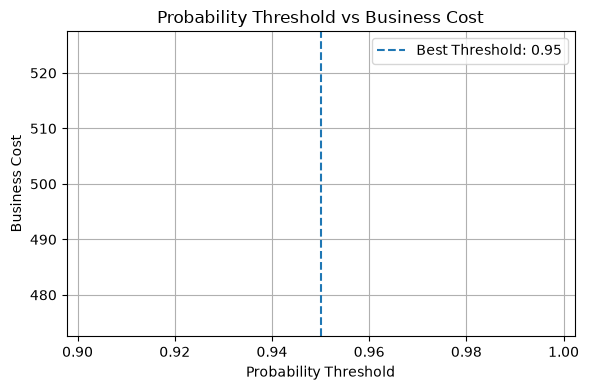

In [17]:
plt.figure(figsize=(6,4))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Business_Cost"]
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold: {best_threshold:.2f}"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Business Cost")
plt.title("Probability Threshold vs Business Cost")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


VALIDATION BRIER SCORE:
0.2359


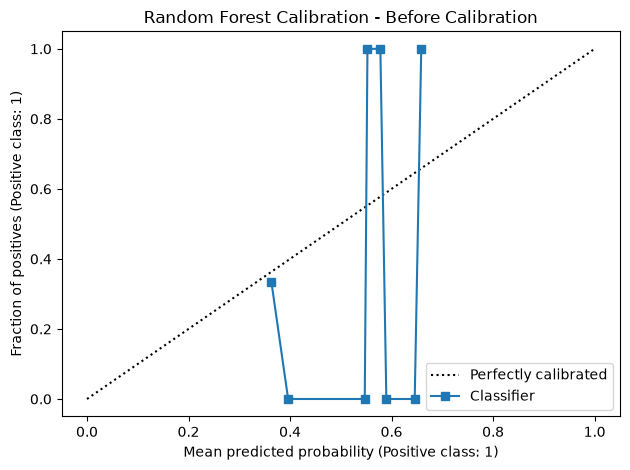

In [18]:

validation_brier = brier_score_loss(
    y_validation,
    validation_probabilities
)

print("\nVALIDATION BRIER SCORE:")
print(round(validation_brier, 4))

CalibrationDisplay.from_predictions(
    y_validation,
    validation_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.title("Random Forest Calibration - Before Calibration")
plt.tight_layout()
plt.show()

In [20]:
x_fit, x_calibration, y_fit, y_calibration = train_test_split(
    x_development,
    y_development,
    test_size=0.20,
    random_state=123,
    stratify=y_development

)

C:\Users\RSC\anaconda3\envs\ml-shap\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(



CALIBRATION COMPARISON
Before Calibration Brier Score: 0.2359
After Calibration Brier Score: 0.2251


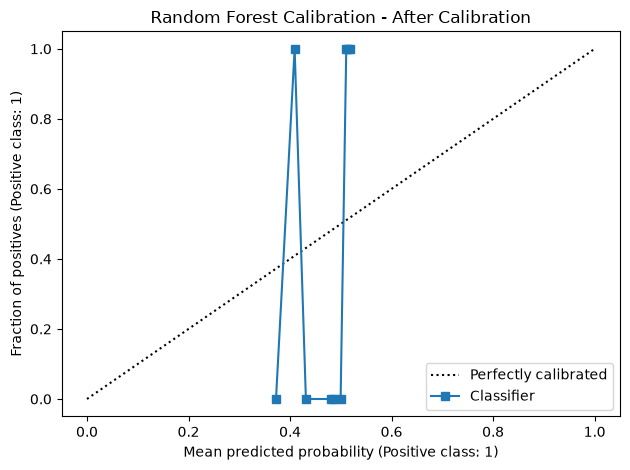


BEST CALIBRATED THRESHOLD:
0.38000000000000006

CALIBRATED THRESHOLD PERFORMANCE:
Threshold         0.38
TN                2.00
FP                4.00
FN                0.00
TP                5.00
Business_Cost    80.00
Name: 33, dtype: float64


In [28]:
calibration_base_model = grid_search.best_estimator_

calibration_base_model.fit(x_fit, y_fit)

calibrated_model = CalibratedClassifierCV(
    estimator=FrozenEstimator(calibration_base_model),
    method="sigmoid"
)

calibrated_model.fit(
    x_calibration,
    y_calibration
)

calibration_probabilities = calibrated_model.predict_proba(
    x_validation
)[:, 1]

calibrated_brier = brier_score_loss(
    y_validation,
    calibration_probabilities
)

print("\nCALIBRATION COMPARISON")

print(
    "Before Calibration Brier Score:",
    round(validation_brier, 4)
)

print(
    "After Calibration Brier Score:",
    round(calibrated_brier, 4)
)

CalibrationDisplay.from_predictions(
    y_validation,
    calibration_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.title("Random Forest Calibration - After Calibration")
plt.tight_layout()
plt.show()

calibrated_threshold_results = []

for threshold in thresholds:

    predictions = (
        calibration_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1]
    ).ravel()

    business_cost = (
        FN_COST * fn +
        FP_COST * fp
    )

    calibrated_threshold_results.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Business_Cost": business_cost
    })

calibrated_threshold_df = pd.DataFrame(
    calibrated_threshold_results
)

best_calibrated_row = calibrated_threshold_df.loc[
    calibrated_threshold_df["Business_Cost"].idxmin()
]

best_calibrated_threshold = best_calibrated_row["Threshold"]

print("\nBEST CALIBRATED THRESHOLD:")
print(best_calibrated_threshold)

print("\nCALIBRATED THRESHOLD PERFORMANCE:")
print(best_calibrated_row)


In [30]:
# Evaluation

test_probabilities = calibrated_model.predict_proba(
    x_test
)[:, 1]

test_predictions = (
    test_probabilities >= best_calibrated_threshold
).astype(int)

print("\n========== FINAL TEST RESULTS ==========")

print(
    "Precision:",
    round(precision_score(
        y_test, test_predictions, zero_division=0
    ), 4)
)

print(
    "Recall:",
    round(recall_score(
        y_test, test_predictions, zero_division=0
    ), 4)
)

print(
    "F1 Score:",
    round(f1_score(
        y_test, test_predictions, zero_division=0
    ), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(
        y_test, test_probabilities
    ), 4)
)

print(
    "Brier Score:",
    round(brier_score_loss(
        y_test, test_probabilities
    ), 4)
)

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, test_predictions))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))


========== FINAL TEST RESULTS ==========
Precision: 0.5455
Recall: 1.0
F1 Score: 0.7059
ROC-AUC: 0.6
Brier Score: 0.2524

CONFUSION MATRIX:
[[0 5]
 [0 6]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         5
           1       0.55      1.00      0.71         6

    accuracy                           0.55        11
   macro avg       0.27      0.50      0.35        11
weighted avg       0.30      0.55      0.39        11



In [ ]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

final_business_cost = (
    FN_COST * fn +
    FP_COST * fp
)

print("\n========== FINAL BUSINESS COST ==========")
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)
print("True Negatives:", tn)
print("Total Business Cost:", final_business_cost)

In [31]:
customer_results = x_test.copy()

customer_results["Actual_Churn"] = y_test

customer_results["Churn_Probability"] = test_probabilities

customer_results["Predicted_Churn"] = test_predictions

customer_results["Churn_Risk"] = pd.cut(
    customer_results["Churn_Probability"],
    bins=[-0.001, 0.30, 0.70, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print("\nCUSTOMER CHURN RISK:")
print(customer_results.head(5))


CUSTOMER CHURN RISK:
    AverageOrderValue  Monetary  PurchaseTrend  Actual_Churn  \
10                512       512             -1             0   
38                160       321              0             0   
18                342       684              0             0   
32                238       238              0             1   
33                822       822             -1             1   

    Churn_Probability  Predicted_Churn   Churn_Risk  
10           0.452220                1  Medium Risk  
38           0.467169                1  Medium Risk  
18           0.492553                1  Medium Risk  
32           0.472731                1  Medium Risk  
33           0.430424                1  Medium Risk  


In [33]:
OUTPUT_DIR = Path("churn_tuning_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

threshold_df.to_csv(
    OUTPUT_DIR / "threshold_business_costs.csv",
    index=False
)

calibrated_threshold_df.to_csv(
    OUTPUT_DIR / "calibrated_threshold_business_costs.csv",
    index=False
)

customer_results.to_csv(
    OUTPUT_DIR / "final_customer_churn_predictions.csv",
    index=True
)

pd.DataFrame([{
    "Best_Parameters": str(grid_search.best_params_),
    "Best_Threshold": best_calibrated_threshold,
    "Validation_Brier_Before": validation_brier,
    "Validation_Brier_After": calibrated_brier,
    "Test_ROC_AUC": roc_auc_score(y_test, test_probabilities),
    "Test_Brier_Score": brier_score_loss(y_test, test_probabilities)
}]).to_csv(
    OUTPUT_DIR / "final_model_summary.csv",
    index=False
)

print("\nAll tuning and evaluation outputs saved successfully!")


All tuning and evaluation outputs saved successfully!
